# PieceSpice — Notebook 02: Piecewise Approximation & Tier-2 Model

Turns the **real extracted vendor curves** (notebook 01 outputs) into
a synthesized Tier-2 CPWL MOSFET subcircuit:

1. Adaptive PWL fit of the transfer characteristic → Vth/gfs parameters
2. RDP compression of the output family → lean breakpoint sets
3. Charge integration of Coss → Q(V), equivalent caps, SPICE table
4. Tanh-knee smoothing → continuous Jacobians for robust Newton
5. Full Tier-2 synthesis and validation against the vendor golden

In [1]:
# PieceSpice — Notebook 02: Piecewise Approximation & Tier-2 Model
# (M3.8) Real vendor data -> PWL fits -> charge tables -> Tier-2 subcircuit.

import sys, os
from pathlib import Path
REPO_ROOT = Path.cwd()
if REPO_ROOT.name == 'notebooks':
    REPO_ROOT = REPO_ROOT.parent
sys.path.insert(0, str(REPO_ROOT))
os.chdir(REPO_ROOT)

VENDOR = "csd16412q5a"   # any vendor with completed M2 outputs

import numpy as np
import matplotlib.pyplot as plt
from config.yaml_io import load_input, load_output
from common.plotting import setup_style
setup_style()

cfg = load_input(VENDOR)
print(f"Vendor: {VENDOR} ({cfg['device']})")

Vendor: csd16412q5a (csd16412q5a)


---
## 1 · Transfer Characteristic — Adaptive PWL Fit

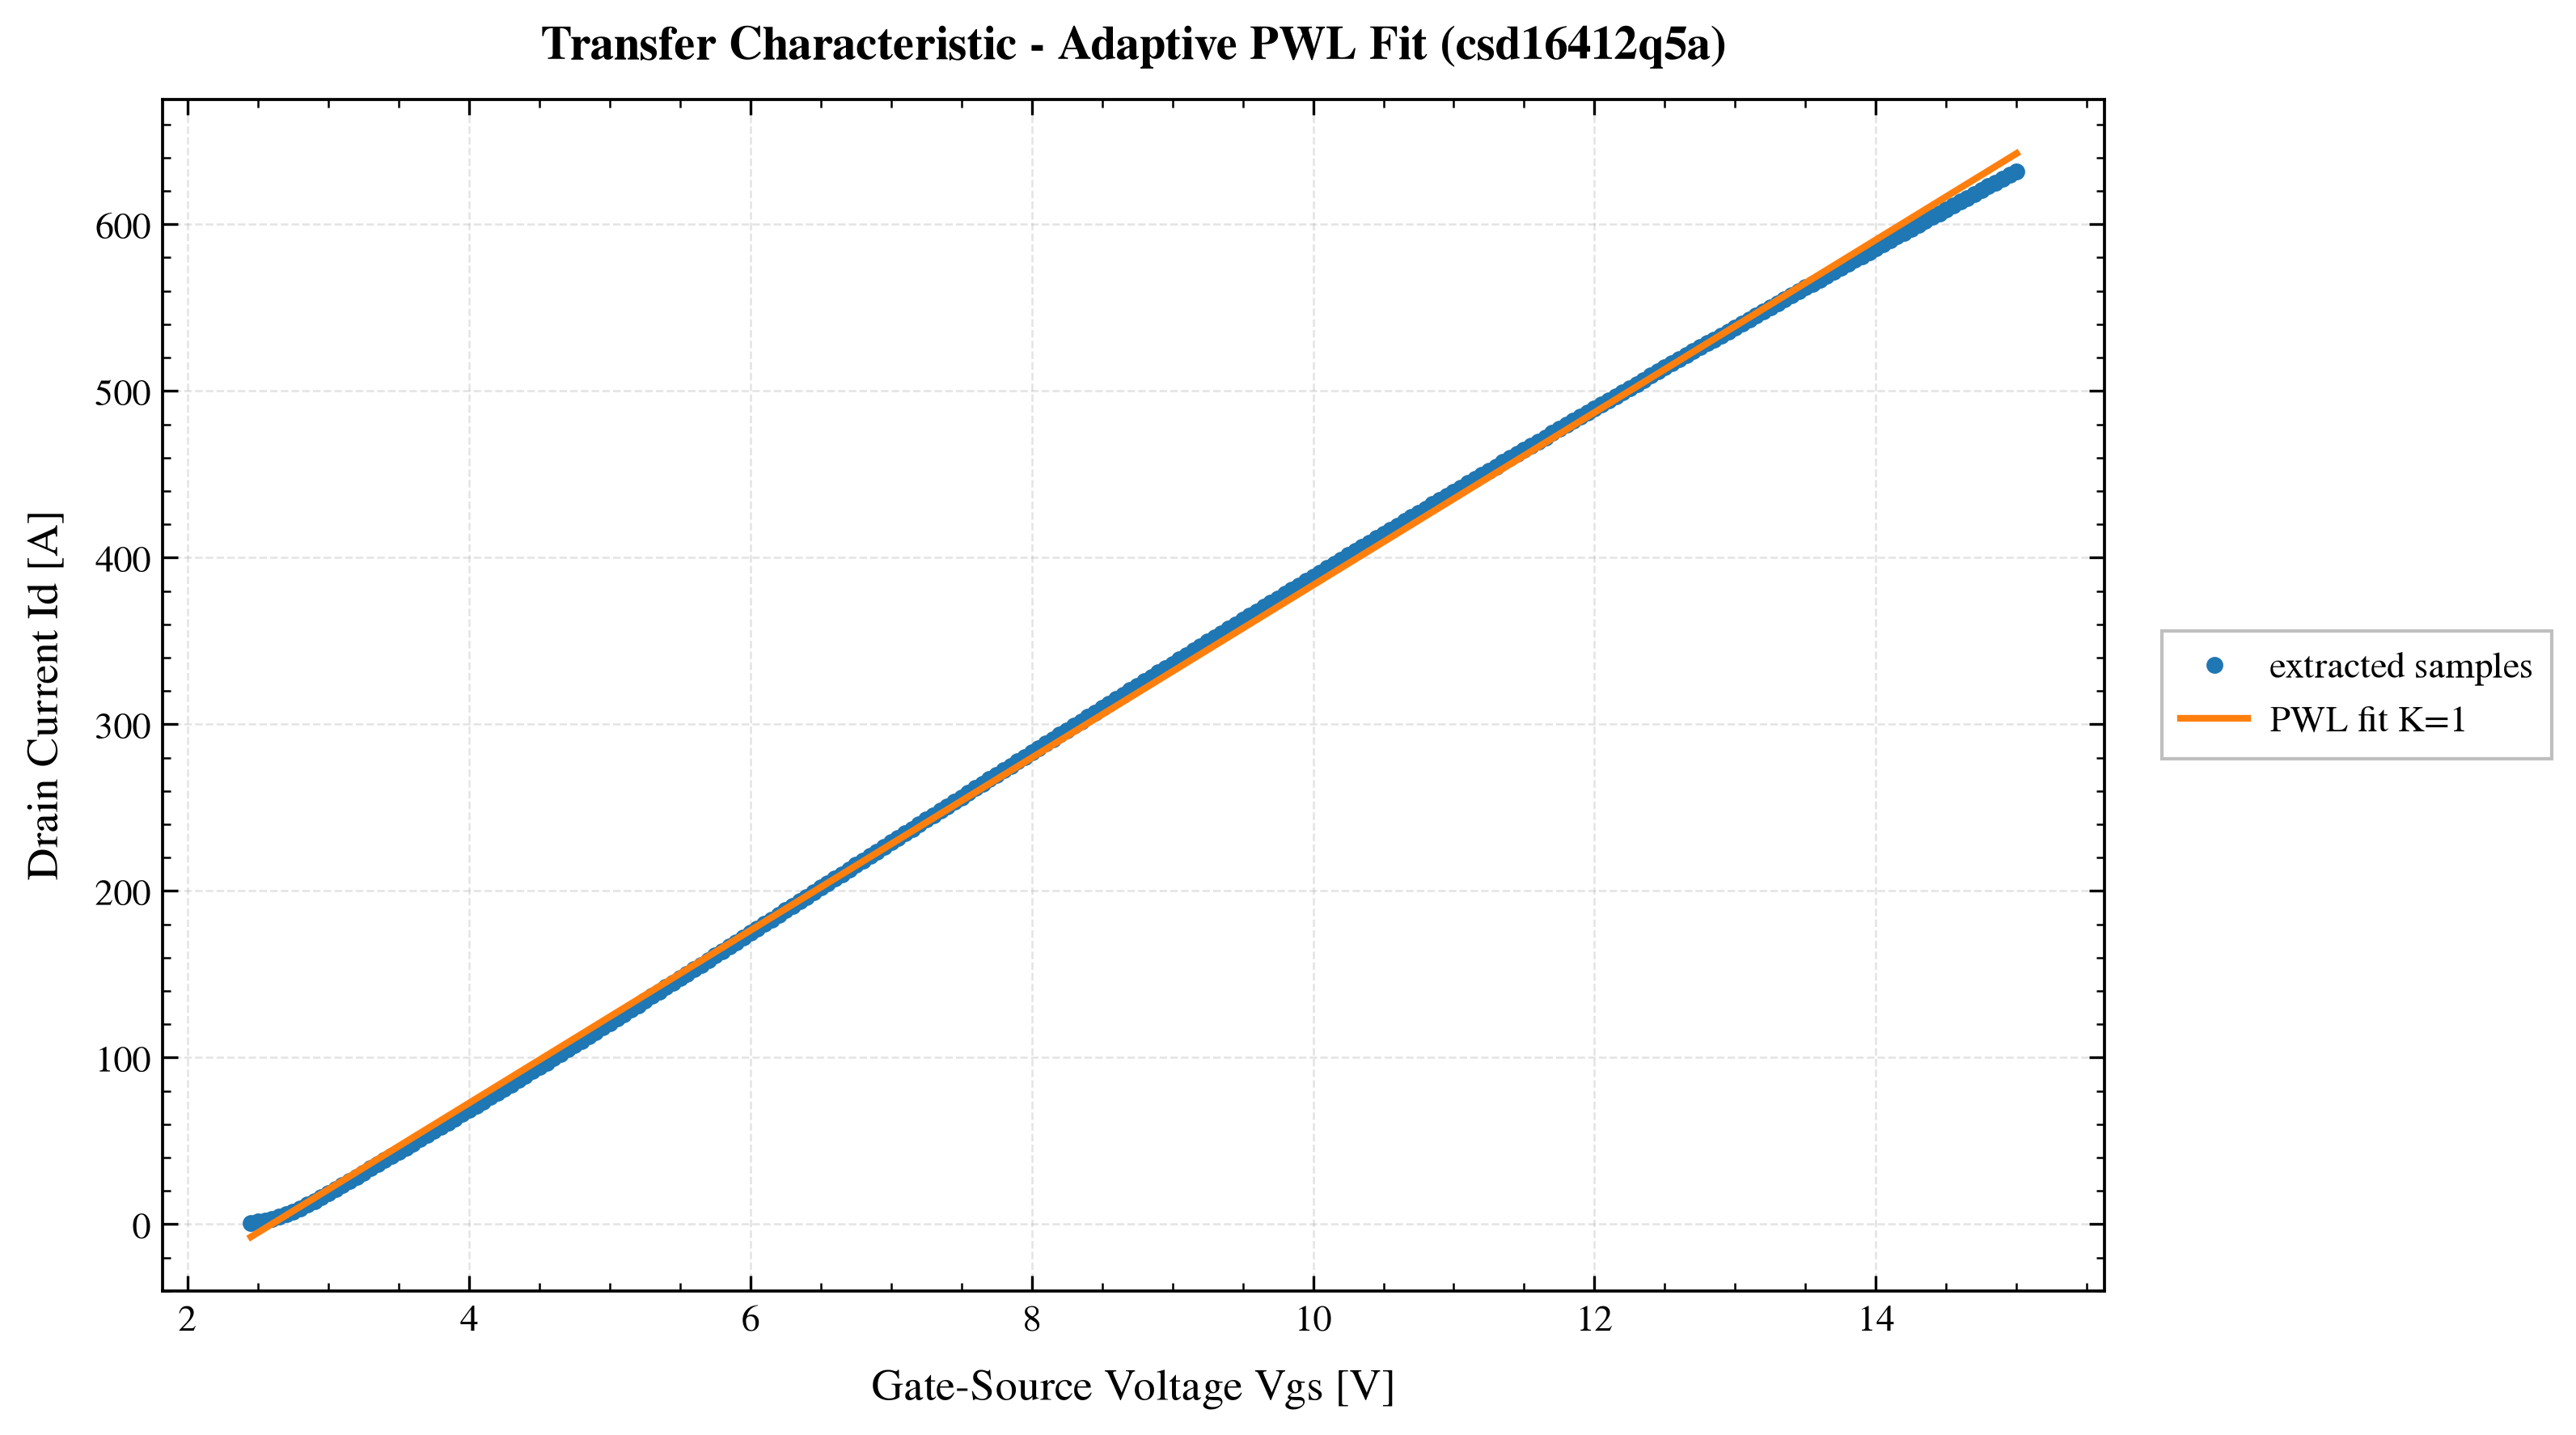

PWL K=1: RMSE=4.006, max|e|=10.64, breaks=[ 2.45 15.  ]
stop_reason : tolerance_met
relative RMSE: 0.635% of span


In [2]:
# --- Fit the transfer characteristic with adaptive PWL (M3.1) ---
from approximation.pwlf_fit import fit_adaptive

c2 = load_output(VENDOR, "curve2_transfer_characteristic")["extracted"]
vgs = np.asarray(c2["curve_vgs"])
i_d = np.asarray(c2["curve_id"])
mask = i_d > max(1e-7, 0.001 * i_d.max())     # conducting region

fit = fit_adaptive(vgs[mask], i_d[mask], rel_tolerance=0.01)
x_dense = np.linspace(vgs[mask][0], vgs[mask][-1], 400)

fig, ax = plt.subplots(figsize=(10.5, 5.8), layout="constrained")
ax.plot(vgs[mask], i_d[mask], "o", ms=4, label="extracted samples")
ax.plot(x_dense, fit.evaluate(x_dense), lw=2,
        label=f"PWL fit K={fit.n_segments}")
for bp in fit.breakpoints_x[1:-1]:
    ax.axvline(bp, ls=":", color="gray", lw=1)
ax.set_xlabel("Gate-Source Voltage Vgs [V]")
ax.set_ylabel("Drain Current Id [A]")
ax.set_title(f"Transfer Characteristic - Adaptive PWL Fit ({VENDOR})")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()
print(fit.summary())
print(f"stop_reason : {fit.stop_reason}")
rel = fit.rmse / (i_d[mask].max() - i_d[mask].min()) * 100
print(f"relative RMSE: {rel:.3f}% of span")

---
## 2 · Output Family — RDP Compression

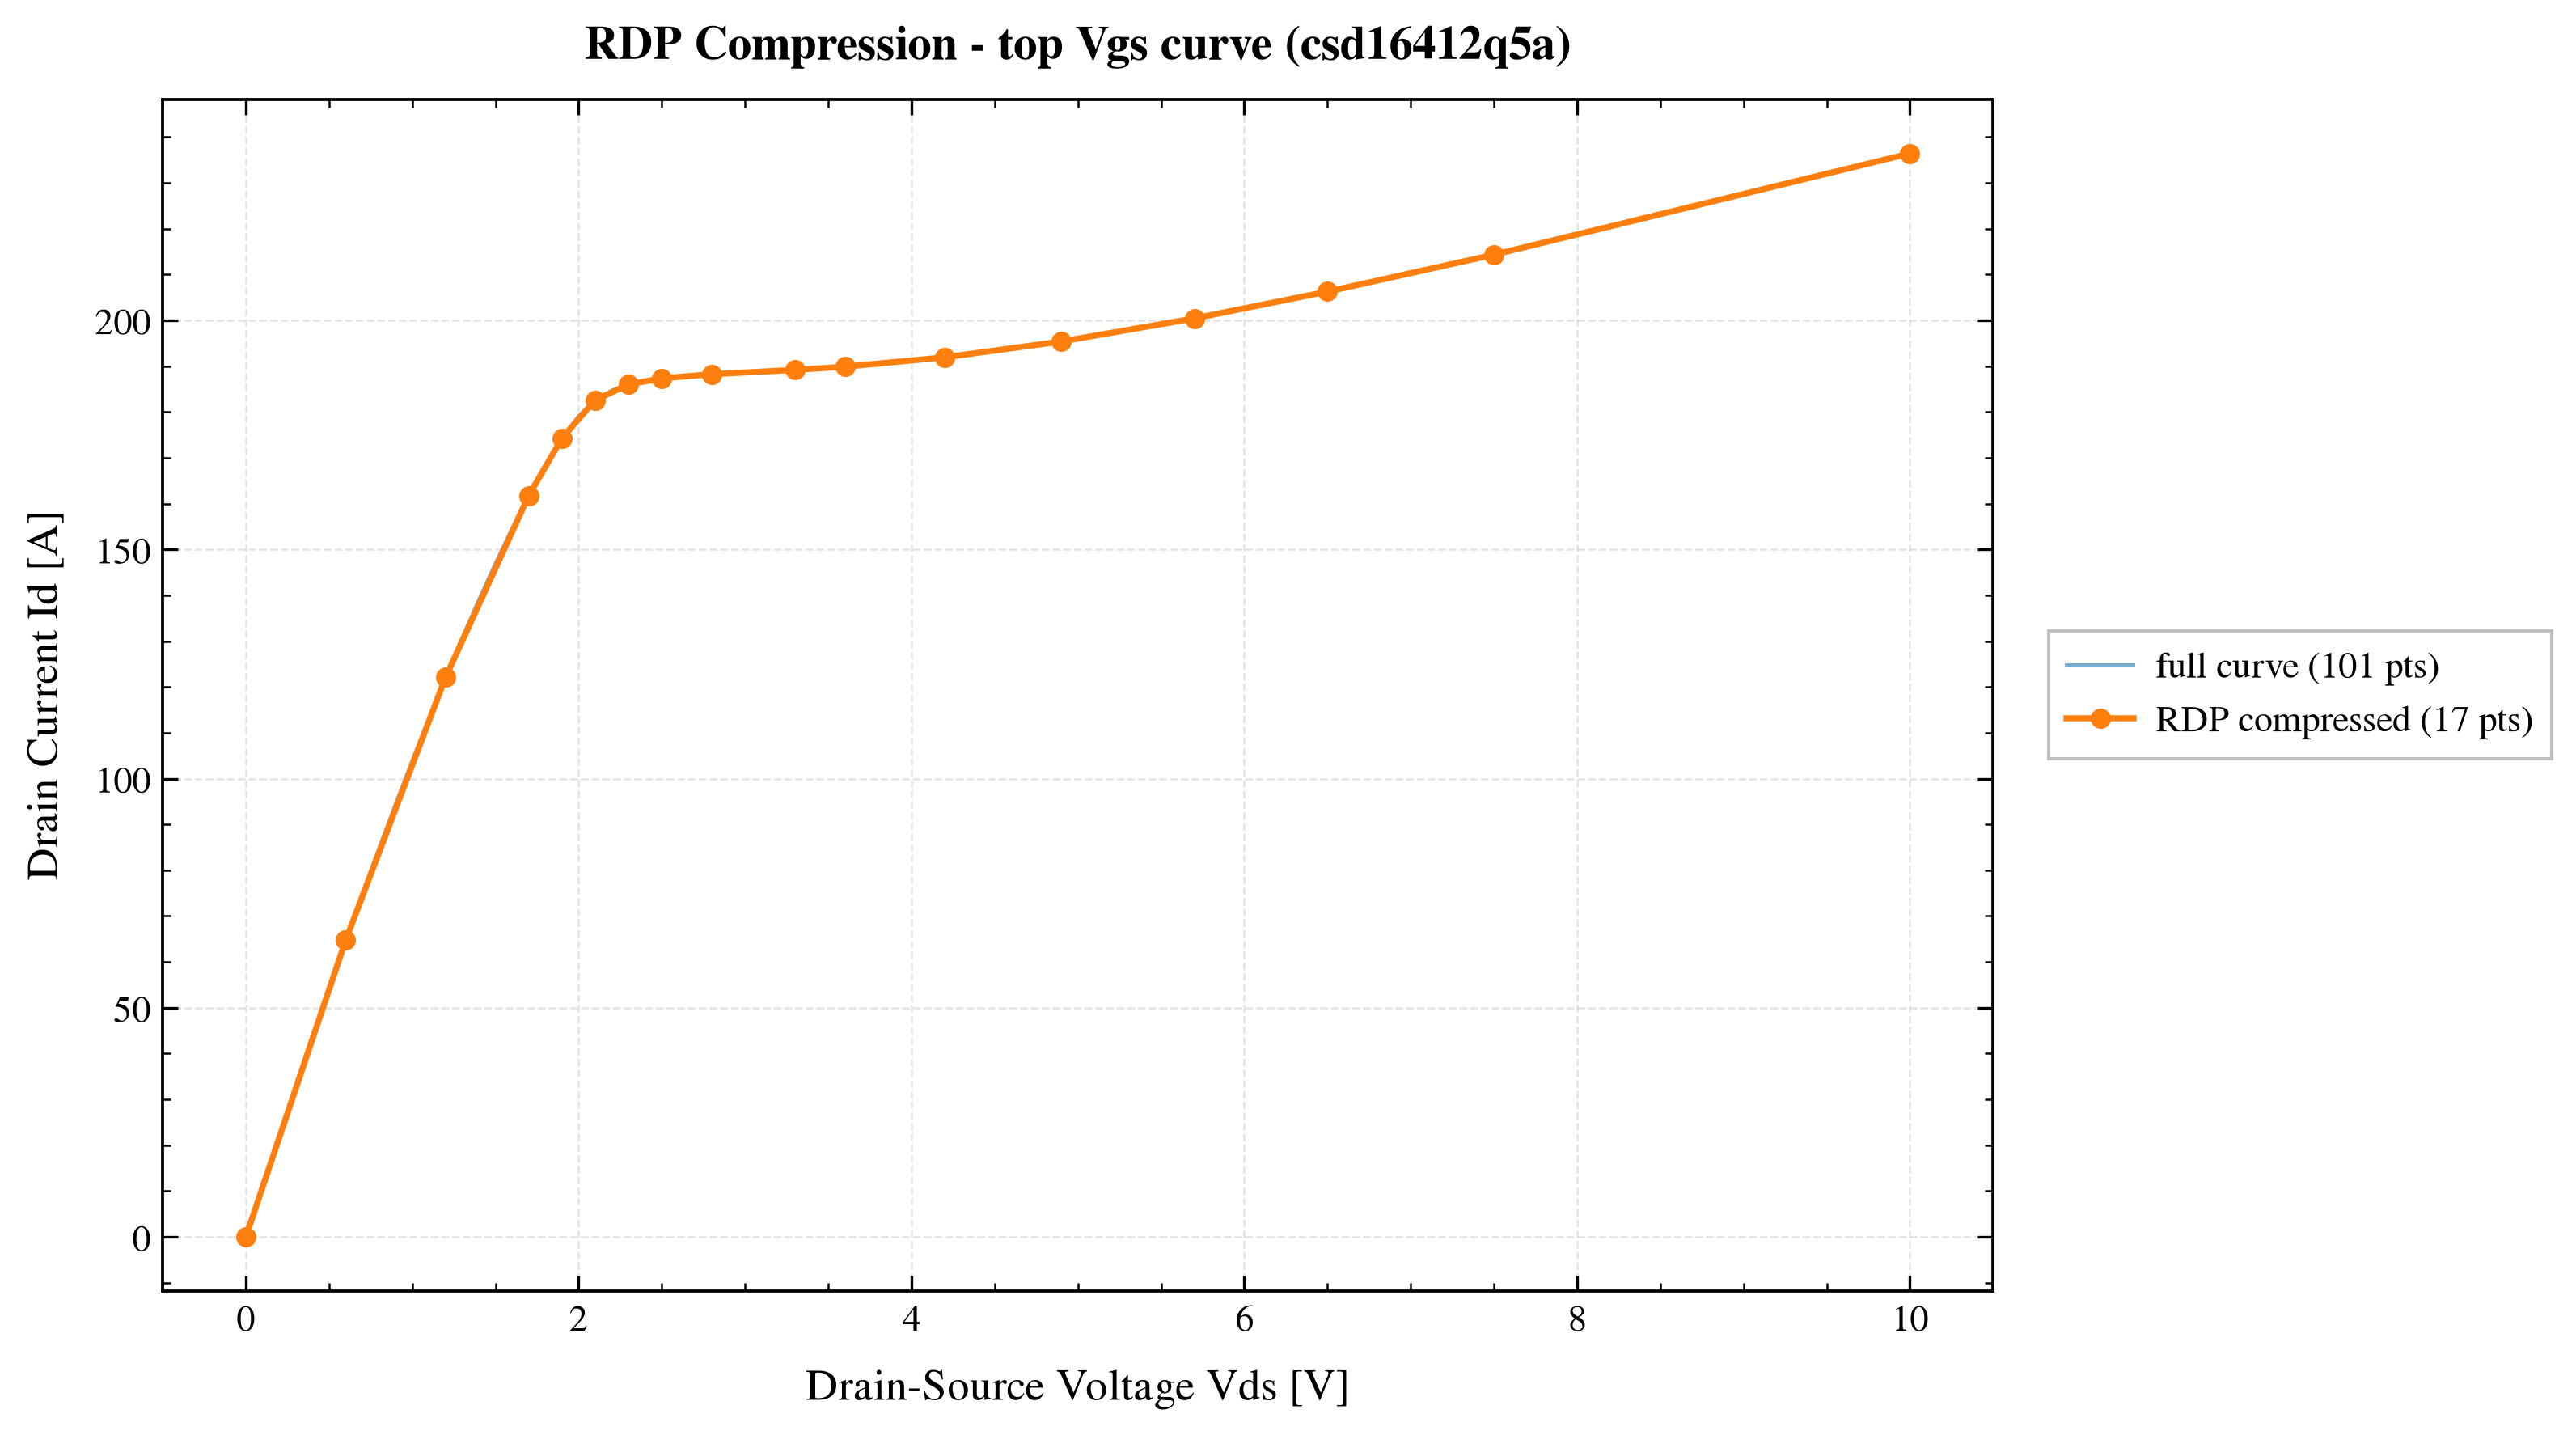

epsilon chosen : 3.625e-02
compression    : 101 -> 17 points (17%)
max deviation  : 1.115e+00 A (budget 2.364e+00 A)


In [3]:
# --- RDP compression of the output characteristics (M3.2) ---
from approximation.rdp_compress import compress_rdp, rdp_epsilon_for_max_error

c1 = load_output(VENDOR, "curve1_output_characteristics")["extracted"]
top_key = sorted(k for k in c1 if k.startswith("curve_id_vgs_"))[-1]
y = np.asarray(c1[top_key])
x = np.linspace(0, float(cfg["conditions"]["Vds_sweep_max"]), len(y))

budget = 0.01 * y.max()
eps = rdp_epsilon_for_max_error(x, y, max_error=budget)
xc, yc = compress_rdp(x, y, epsilon=eps)

fig, ax = plt.subplots(figsize=(10.5, 5.8), layout="constrained")
ax.plot(x, y, lw=1, alpha=0.6, label=f"full curve ({len(x)} pts)")
ax.plot(xc, yc, "o-", ms=5, label=f"RDP compressed ({len(xc)} pts)")
ax.set_xlabel("Drain-Source Voltage Vds [V]")
ax.set_ylabel("Drain Current Id [A]")
ax.set_title(f"RDP Compression - top Vgs curve ({VENDOR})")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()
interp_err = np.max(np.abs(np.interp(x, xc, yc) - y))
print(f"epsilon chosen : {eps:.3e}")
print(f"compression    : {len(x)} -> {len(xc)} points "
      f"({100*len(xc)/len(x):.0f}%)")
print(f"max deviation  : {interp_err:.3e} A (budget {budget:.3e} A)")

---
## 3 · Charge Integration — Qoss(V) & PWL Table

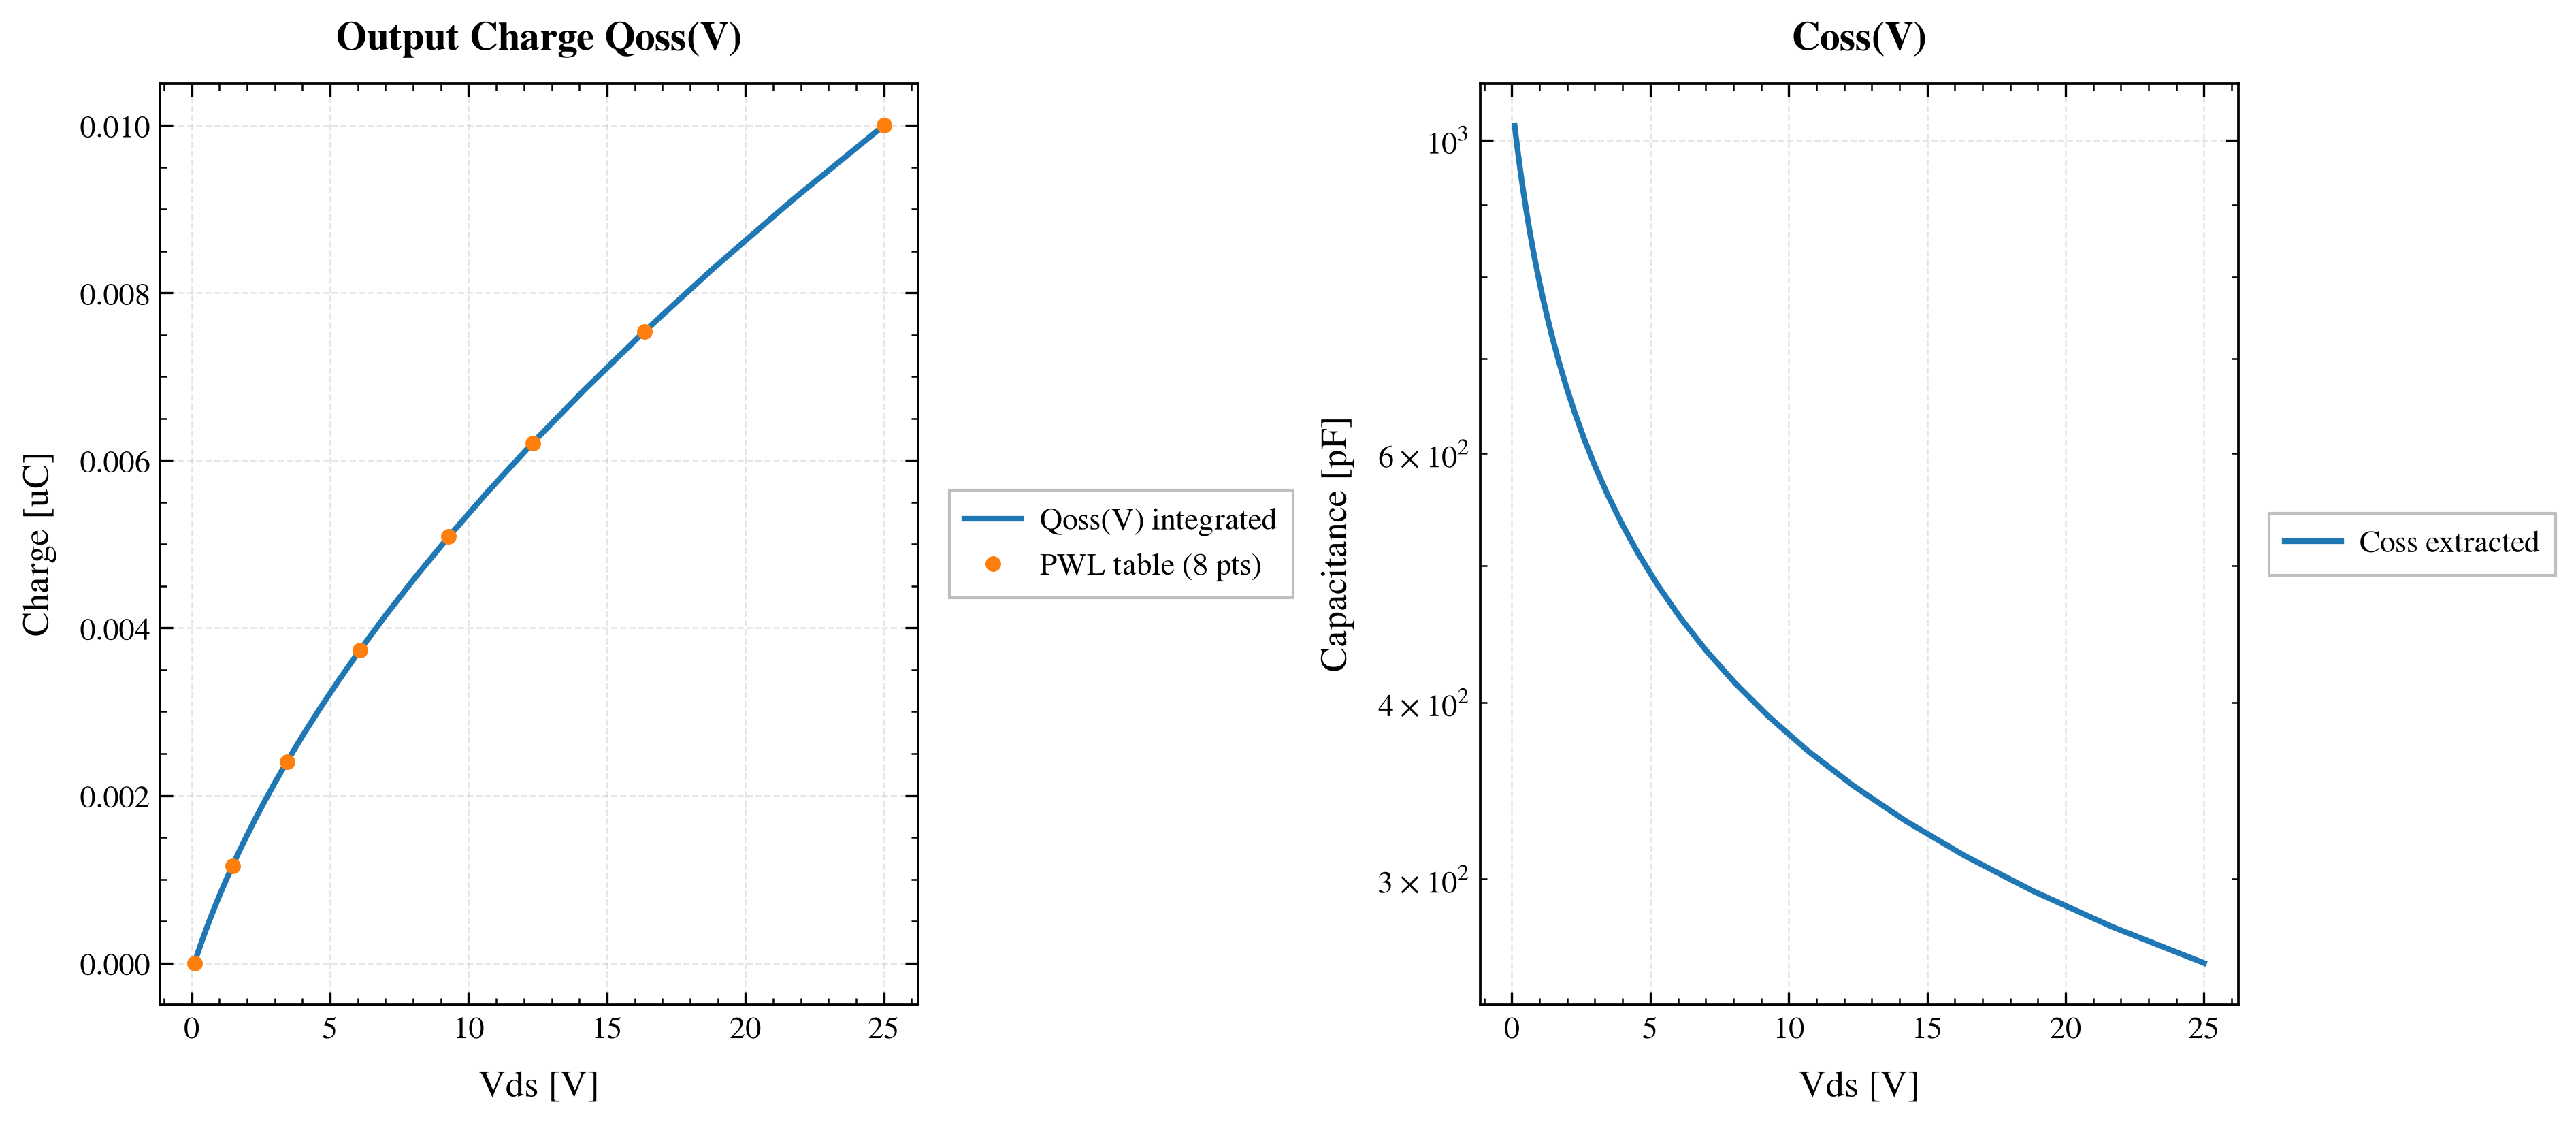

Qoss(25V)     : 0.0100 uC
Eoss(25V)     : 0.1020 uJ
C_eq(charge)   : 0.4000 nF
C_eq(energy)   : 0.3264 nF
PWL table      : 8 pts, max err 0.0496 nC


In [4]:
# --- Charge model: Qoss(V), equivalent caps, PWL table (M3.3) ---
from approximation.charge_model import (
    integrate_charge, pwl_charge_segments, synthesize_charge_source)

cond = cfg["conditions"]
cap_ref = float(cond.get("Cap_ref_Vds", 25.0))

# Re-extract Coss at full resolution for the charge table
from parser.netlist import resolve_pin_connections
from simulation.testbenches.capacitance import CapacitanceTestbench
lib = Path(cfg["library"]).resolve()
roles = resolve_pin_connections(lib, cfg["subcircuit"],
    pin_order_semantic=cfg.get("pins", {}).get("pin_order_semantic"))
_, coss, _ = CapacitanceTestbench(f_meas=cond.get("F_meas")).run(
    lib, cfg["subcircuit"], vds_min=cond["Vds_cap_min"],
    vds_max=cond["Vds_cap_max"], points=cond["Cap_points"],
    pin_roles=roles)

cm = integrate_charge(np.asarray(coss.x_data), np.asarray(coss.y_data),
                      v_ref=cap_ref)
table = pwl_charge_segments(coss.x_data, coss.y_data)

fig, axs = plt.subplots(1, 2, figsize=(12.5, 5.4), layout="constrained")
axs[0].plot(cm.v, cm.q * 1e6, lw=2, label="Qoss(V) integrated")
axs[0].plot(table.v_breaks, np.asarray(table.q_values) * 1e6, "o",
            label=f"PWL table ({table.n_points} pts)")
axs[0].set_xlabel("Vds [V]"); axs[0].set_ylabel("Charge [uC]")
axs[0].set_title("Output Charge Qoss(V)")
axs[0].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))

axs[1].semilogy(cm.v, cm.c * 1e12, lw=2, label="Coss extracted")
axs[1].set_xlabel("Vds [V]"); axs[1].set_ylabel("Capacitance [pF]")
axs[1].set_title("Coss(V)")
axs[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()

print(f"Qoss({cap_ref:g}V)     : {cm.q[-1]*1e6:.4f} uC")
print(f"Eoss({cap_ref:g}V)     : {cm.e[-1]*1e6:.4f} uJ")
print(f"C_eq(charge)   : {cm.c_eq_charge*1e9:.4f} nF")
print(f"C_eq(energy)   : {cm.c_eq_energy*1e9:.4f} nF")
print(f"PWL table      : {table.n_points} pts, "
      f"max err {table.max_abs_error_c*1e9:.4f} nC")

---
## 4 · Knee Smoothing — Hard PWL vs C¹ tanh

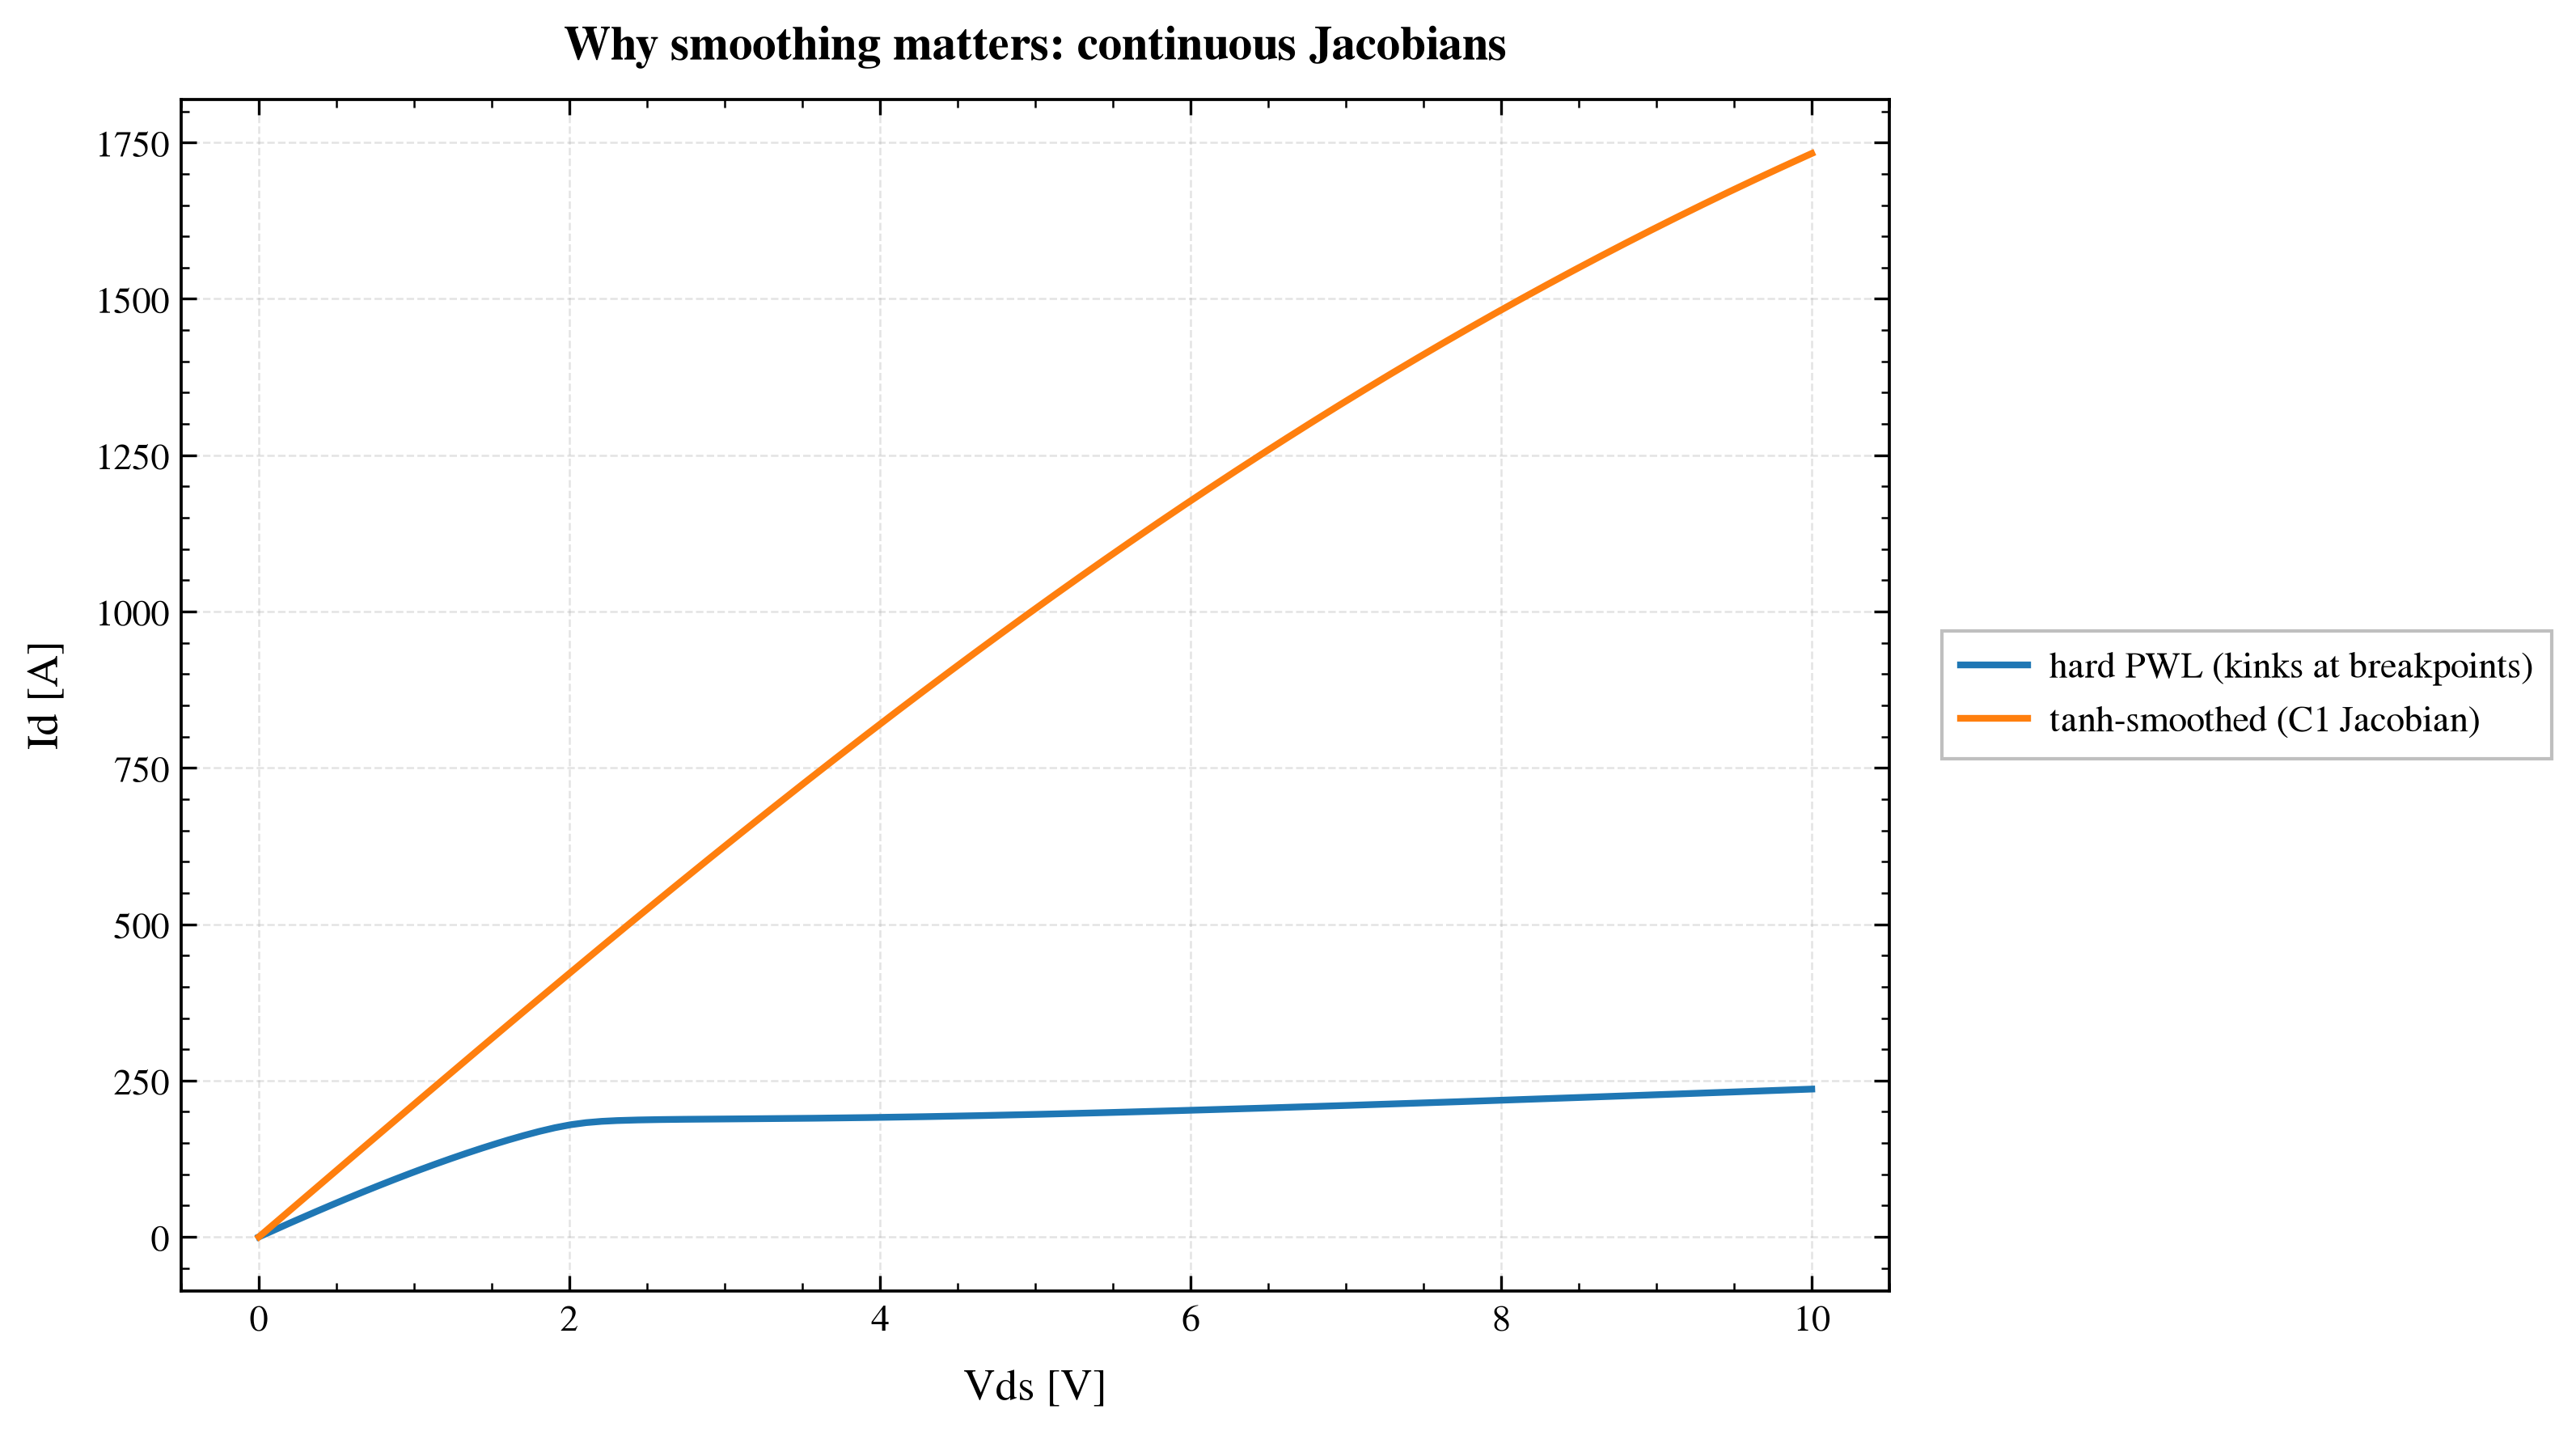

In [5]:
# --- C1 knee smoothing demo (M3.4): hard PWL vs smoothed channel ---
from approximation.smoother import tanh_saturation

vds = np.linspace(0, float(cond["Vds_sweep_max"]), 300)
ids_hard = np.interp(vds, x, y)                      # hard PWL (compressed)
gm_est = y.max() / vds[-1] * 3                        # rough saturation gm
ids_smooth = tanh_saturation(vds, v_ds_sat=max(y.max()*0.05, 0.1), gm=gm_est*3)

fig, ax = plt.subplots(figsize=(10.5, 5.8), layout="constrained")
ax.plot(vds, ids_hard, lw=2, label="hard PWL (kinks at breakpoints)")
ax.plot(vds, ids_smooth, lw=2, label="tanh-smoothed (C1 Jacobian)")
ax.set_xlabel("Vds [V]"); ax.set_ylabel("Id [A]")
ax.set_title("Why smoothing matters: continuous Jacobians")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()

---
## 5 · Tier-2 Synthesis & Validation vs Golden

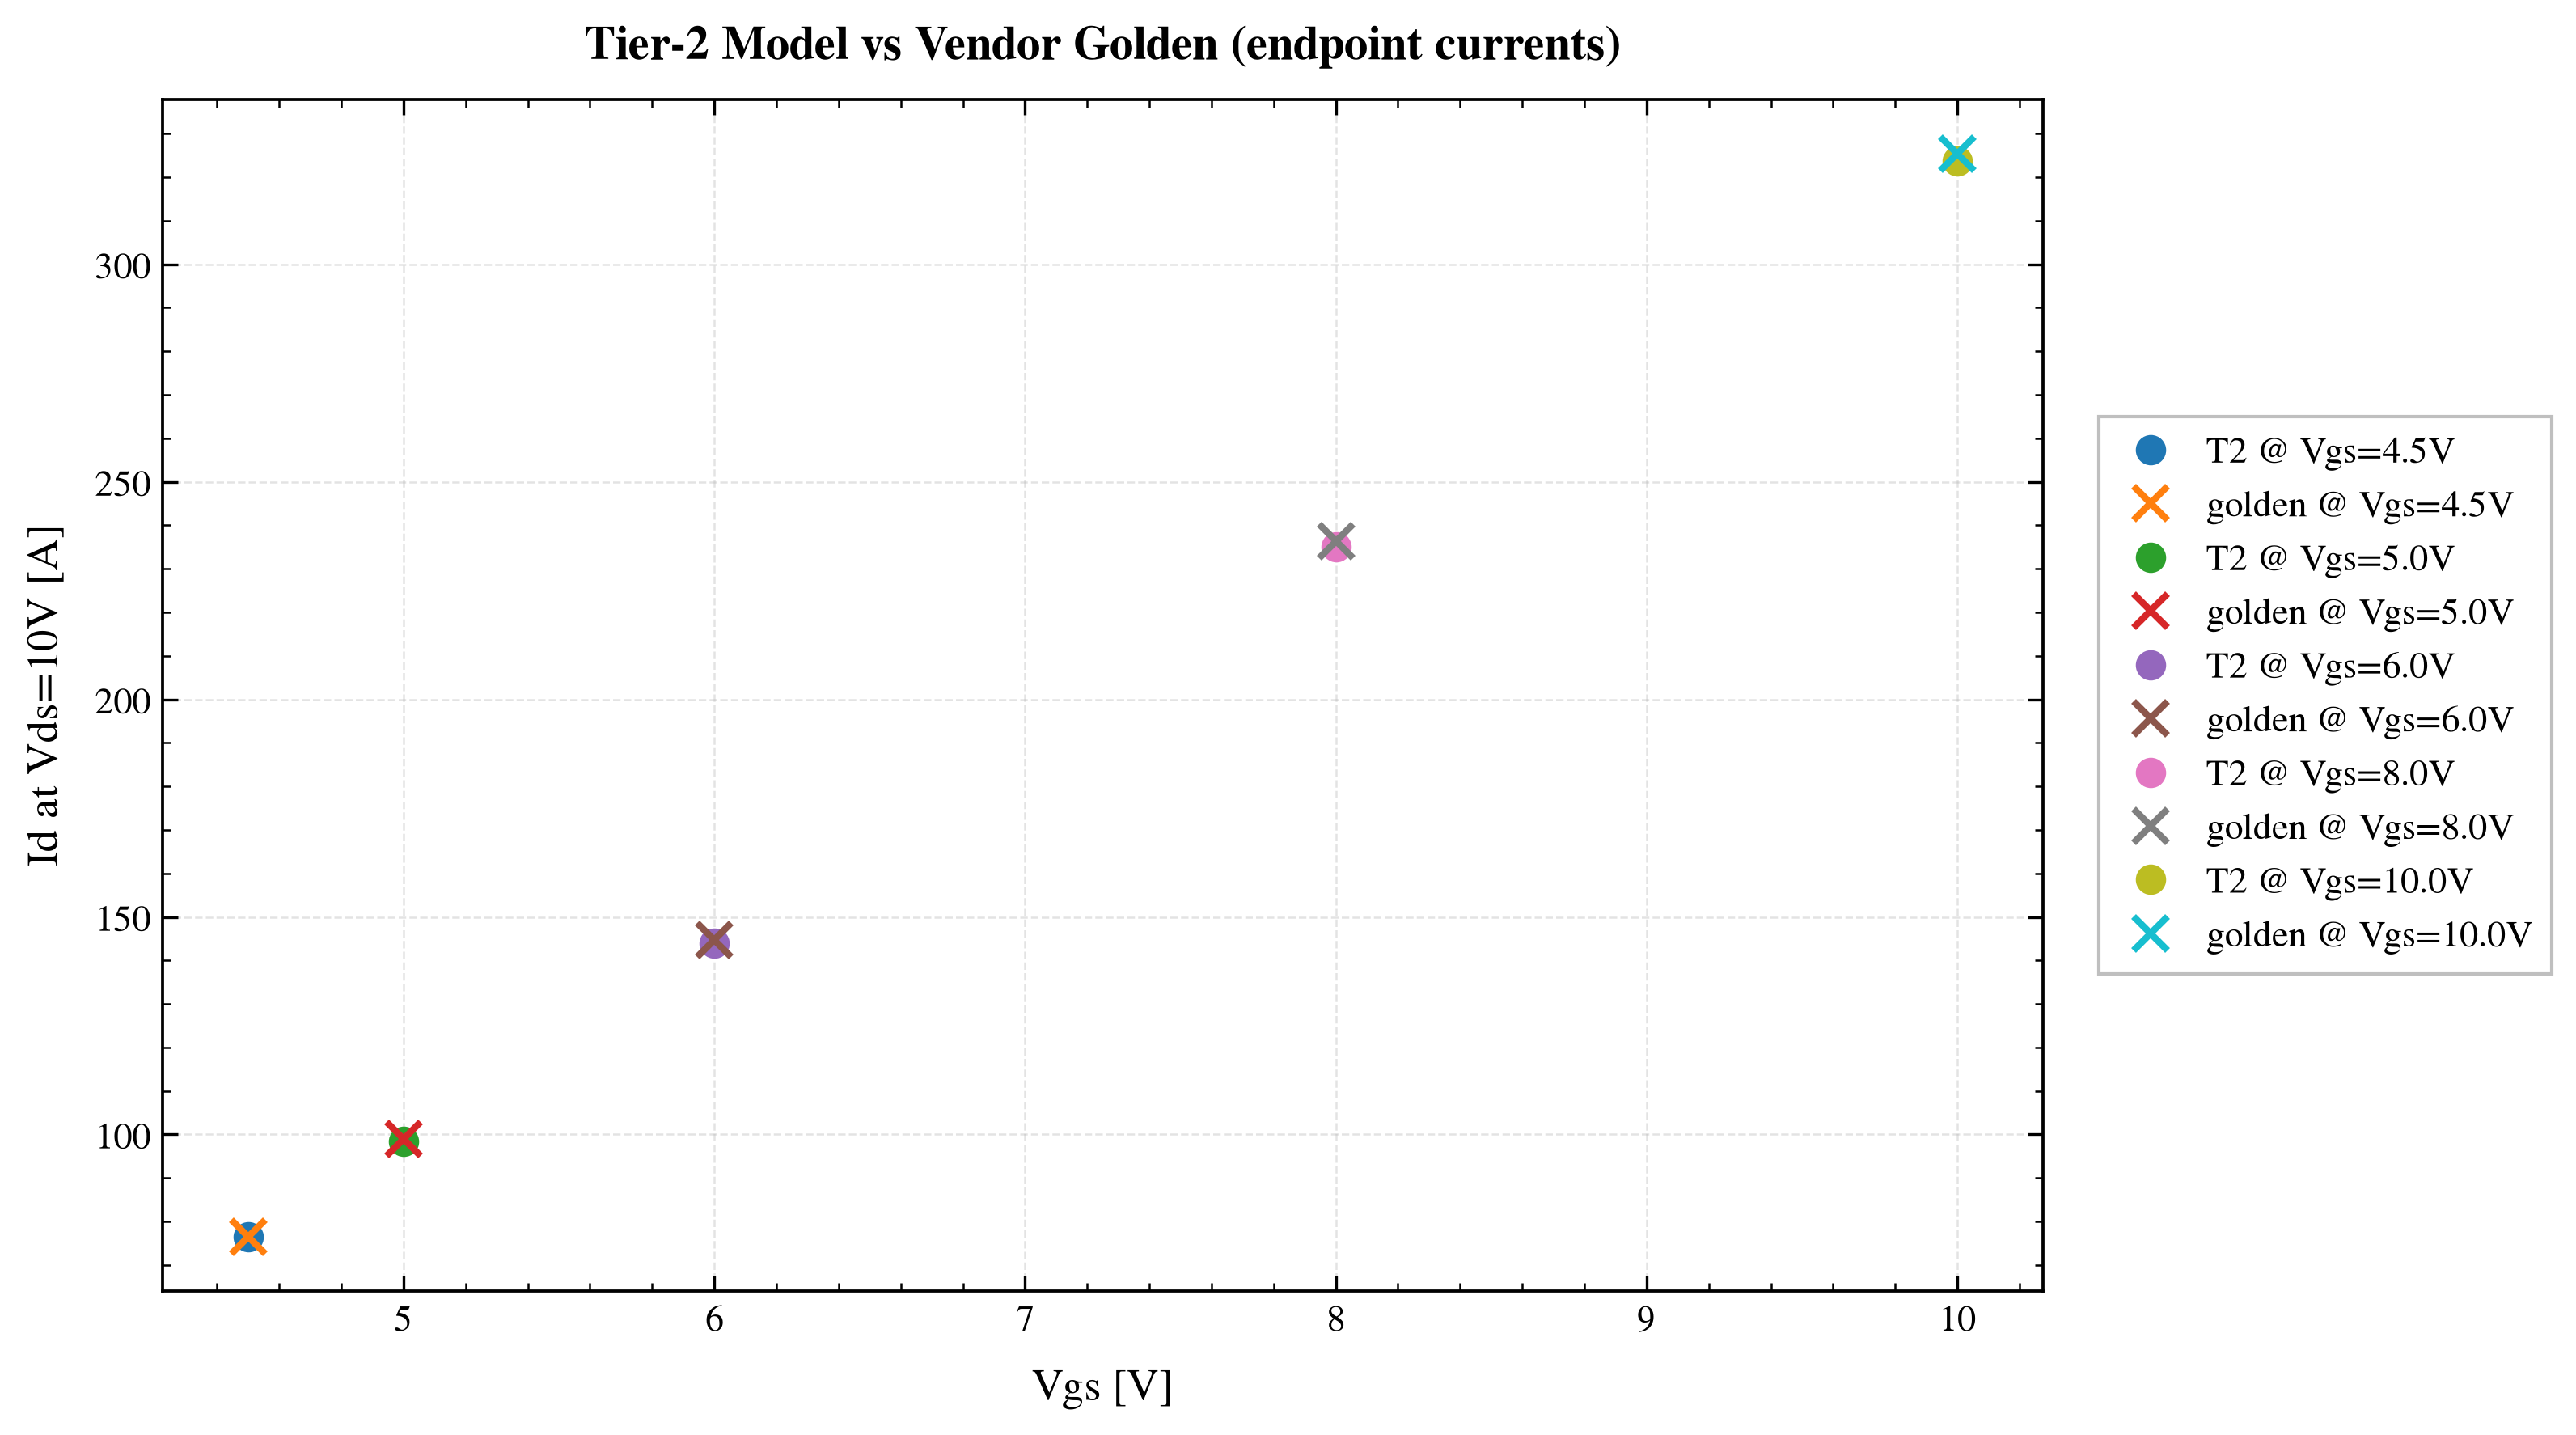

   Vgs     Golden     Tier-2    Error
   4.5      76.50      76.45    0.07%
   5.0      98.95      98.44    0.51%
   6.0     144.73     143.97    0.52%
   8.0     236.39     235.14    0.53%
  10.0     325.46     323.79    0.51%

Worst endpoint error: 0.53%  (target < 5%)


In [6]:
# --- Synthesize the Tier-2 subcircuit and validate vs golden (M3.5/3.6) ---
from pipeline.fitting import fit_pwl_model
from PySpice.Spice.Netlist import Circuit

lib = fit_pwl_model(VENDOR)
name = f"{cfg['device']}_PIECESPACE_T2".replace("PIECESPICE_T2",
                                                "_PIECESPICE_T2")
name = lib.stem   # actual subckt name inside the file

golden_keys = sorted((float(k[len("curve_id_vgs_"):-2]), k)
                     for k in c1 if k.startswith("curve_id_vgs_"))

fig, ax = plt.subplots(figsize=(10.5, 5.8), layout="constrained")
rows = []
for vgs_val, key in golden_keys:
    golden_y = np.asarray(c1[key])
    c = Circuit(f"t2_{vgs_val}")
    c.include(str(lib))
    from common.types import PWLModelSpec  # noqa (name registered)
    c.X("M1", name, "d", "g", c.gnd)
    c.V("ds", "d", c.gnd, 10)
    c.V("gs", "g", c.gnd, vgs_val)
    op = c.simulator(temperature=25, nominal_temperature=25).operating_point()
    i_t2 = abs(float(op.branches["vds"][0]))
    i_golden_10v = float(golden_y[-1])
    rel = abs(i_t2 - i_golden_10v) / max(abs(i_golden_10v), 1e-9) * 100
    rows.append((vgs_val, i_golden_10v, i_t2, rel))
    ax.plot(vgs_val, i_t2, "o", ms=8, label=f"T2 @ Vgs={vgs_val}V")
    ax.plot(vgs_val, i_golden_10v, "x", ms=10, mew=2,
            label=f"golden @ Vgs={vgs_val}V")

ax.set_xlabel("Vgs [V]")
ax.set_ylabel("Id at Vds=10V [A]")
ax.set_title("Tier-2 Model vs Vendor Golden (endpoint currents)")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()

print(f"{'Vgs':>6} {'Golden':>10} {'Tier-2':>10} {'Error':>8}")
worst = 0.0
for v, g, t2, rel in rows:
    print(f"{v:6.1f} {g:10.2f} {t2:10.2f} {rel:7.2f}%")
    worst = max(worst, rel)
print(f"\nWorst endpoint error: {worst:.2f}%  (target < 5%)")